### **Important Question that Notebook 2: "Feature Engineering" will help us answer:**

##**"What information should we give the HMM so it can infer hidden market regimes?"**

 **Answer:**

#### **A Hidden Markov Model learns from observations rather than labels. Therefore, instead of feeding it raw prices, we engineer economically meaningful features that describe different aspects of market behavior. Returns capture daily price movements, rolling volatility measures realized risk, momentum identifies trend persistence, rolling correlation captures changing relationships between asset classes, and the VIX provides forward-looking information about market fear. Since hidden regimes manifest through changes in all these characteristics simultaneously, combining complementary features enables the HMM to distinguish Bull, Bear, and Crisis regimes much more effectively than relying on any single variable.**

In [1]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
plt.style.use("ggplot")

TICKERS = ["SPY", "TLT", "GLD", "^VIX"]

prices = yf.download(
    TICKERS,
    start="2005-01-01",
    end="2026-06-30",
    auto_adjust=True,
    progress=False)["Close"]

prices = prices.dropna()
log_returns = np.log(prices / prices.shift(1))
log_returns = log_returns.dropna()

rolling_vol = log_returns["SPY"].rolling(window=63).std() * np.sqrt(252)

rolling_mean = log_returns["SPY"].rolling(window=252).mean()

rolling_var = log_returns["SPY"].rolling(window=252).var()

In [2]:
features = log_returns.copy()
features.head()

Ticker,GLD,SPY,TLT,^VIX
Date,,,,
2005-01-04,-0.006530,-0.012295,-0.010536,-0.007128
2005-01-05,-0.001639,-0.006924,0.005339,0.007838
2005-01-06,-0.012261,0.005071,0.000680,-0.036867
2005-01-07,-0.007382,-0.001434,0.002260,-0.006649
2005-01-10,0.002626,0.004717,0.001581,-0.019462


In [3]:
print("Feature Matrix Shape:", features.shape)
features.info()

Feature Matrix Shape: (5404, 4)
<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 5404 entries, 2005-01-04 to 2026-06-29
Data columns (total 4 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   GLD     5404 non-null   float64
 1   SPY     5404 non-null   float64
 2   TLT     5404 non-null   float64
 3   ^VIX    5404 non-null   float64
dtypes: float64(4)
memory usage: 211.1 KB


In [4]:
features.columns = [
    "GLD_Return",
    "SPY_Return",
    "TLT_Return",
    "VIX_Return"]
features.head()

,GLD_Return,SPY_Return,TLT_Return,VIX_Return
Date,,,,
2005-01-04,-0.006530,-0.012295,-0.010536,-0.007128
2005-01-05,-0.001639,-0.006924,0.005339,0.007838
2005-01-06,-0.012261,0.005071,0.000680,-0.036867
2005-01-07,-0.007382,-0.001434,0.002260,-0.006649
2005-01-10,0.002626,0.004717,0.001581,-0.019462


In [5]:
print(features.isnull().sum())

GLD_Return    0
SPY_Return    0
TLT_Return    0
VIX_Return    0
dtype: int64


In [6]:
# 20-day rolling volatility
rolling_vol_20 = features.rolling(window=20).std()
rolling_vol_20.head(25)

,GLD_Return,SPY_Return,TLT_Return,VIX_Return
Date,,,,
2005-01-04,NaN,NaN,NaN,NaN
2005-01-05,NaN,NaN,NaN,NaN
2005-01-06,NaN,NaN,NaN,NaN
2005-01-07,NaN,NaN,NaN,NaN
2005-01-10,NaN,NaN,NaN,NaN
2005-01-11,NaN,NaN,NaN,NaN
2005-01-12,NaN,NaN,NaN,NaN
2005-01-13,NaN,NaN,NaN,NaN
2005-01-14,NaN,NaN,NaN,NaN


In [7]:
rolling_vol_20.columns = ["GLD_Vol20","SPY_Vol20","TLT_Vol20","VIX_Vol20"]

In [8]:
features = pd.concat([features, rolling_vol_20],axis=1)
features.head(25)

,GLD_Return,SPY_Return,TLT_Return,VIX_Return,GLD_Vol20,SPY_Vol20,TLT_Vol20,VIX_Vol20
Date,,,,,,,,
2005-01-04,-0.006530,-0.012295,-0.010536,-0.007128,NaN,NaN,NaN,NaN
2005-01-05,-0.001639,-0.006924,0.005339,0.007838,NaN,NaN,NaN,NaN
2005-01-06,-0.012261,0.005071,0.000680,-0.036867,NaN,NaN,NaN,NaN
2005-01-07,-0.007382,-0.001434,0.002260,-0.006649,NaN,NaN,NaN,NaN
2005-01-10,0.002626,0.004717,0.001581,-0.019462,NaN,NaN,NaN,NaN
2005-01-11,0.006179,-0.006914,0.005847,-0.003028,NaN,NaN,NaN,NaN
2005-01-12,0.009197,0.003294,0.001344,-0.048942,NaN,NaN,NaN,NaN
2005-01-13,0.000000,-0.008045,0.009582,0.022048,NaN,NaN,NaN,NaN
2005-01-14,-0.006594,0.005258,-0.000110,-0.032452,NaN,NaN,NaN,NaN


In [9]:
features.isnull().sum()

,0
GLD_Return,0
SPY_Return,0
TLT_Return,0
VIX_Return,0
GLD_Vol20,19
SPY_Vol20,19
TLT_Vol20,19
VIX_Vol20,19


In [10]:
features = features.dropna()
features.head()
print(features.shape)

(5385, 8)


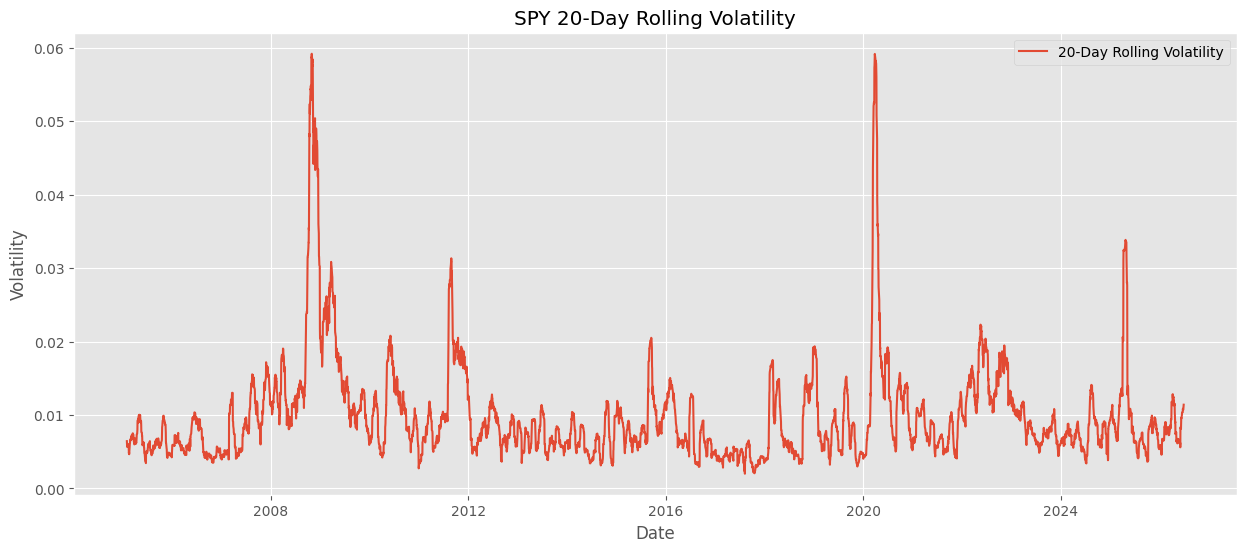

In [11]:
plt.figure(figsize=(15,6))
plt.plot(features.index,
         features["SPY_Vol20"],
         label="20-Day Rolling Volatility")

plt.title("SPY 20-Day Rolling Volatility")
plt.xlabel("Date")
plt.ylabel("Volatility")
plt.legend()
plt.show()

In [12]:
rolling_vol_63 = (features[["GLD_Return", "SPY_Return", "TLT_Return", "VIX_Return"]].rolling(window=63).std())
rolling_vol_63.columns = ["GLD_Vol63","SPY_Vol63","TLT_Vol63","VIX_Vol63",]

In [13]:
features = pd.concat([features, rolling_vol_63],axis=1)

In [14]:
features = features.dropna()
print(features.shape)
features.head()

(5323, 12)


,GLD_Return,SPY_Return,TLT_Return,VIX_Return,GLD_Vol20,SPY_Vol20,TLT_Vol20,VIX_Vol20,GLD_Vol63,SPY_Vol63,TLT_Vol63,VIX_Vol63
Date,,,,,,,,,,,,
2005-05-02,-0.010901,0.005600,-0.000216,-0.012488,0.006673,0.009962,0.006038,0.096209,0.006903,0.007727,0.006461,0.065075
2005-05-03,-0.002802,0.001716,0.002710,-0.039803,0.006713,0.009901,0.005954,0.096395,0.006903,0.007686,0.006463,0.064753
2005-05-04,0.003269,0.007689,-0.008811,-0.047930,0.006687,0.010038,0.006410,0.096609,0.006912,0.007741,0.006560,0.064929
2005-05-05,0.000233,-0.000341,0.002292,0.009342,0.006675,0.009943,0.006011,0.095317,0.006747,0.007735,0.006565,0.064926
2005-05-06,-0.009130,-0.003154,-0.007440,0.004995,0.006975,0.009699,0.006346,0.095233,0.006820,0.007619,0.006400,0.064569


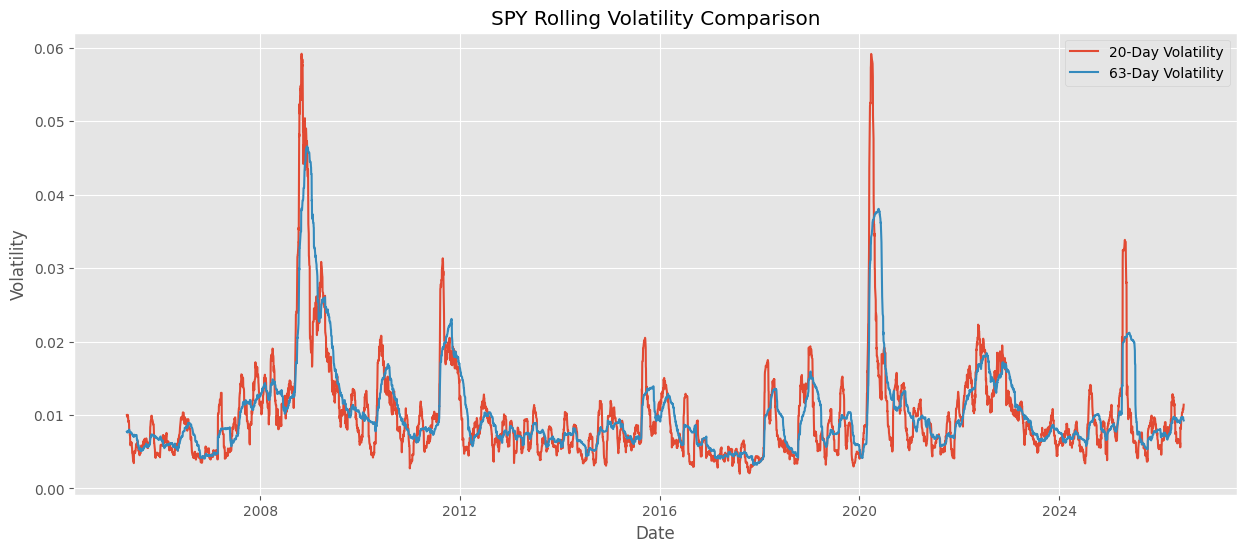

In [15]:
plt.figure(figsize=(15, 6))
plt.plot(features.index, features["SPY_Vol20"], label="20-Day Volatility")
plt.plot(features.index, features["SPY_Vol63"], label="63-Day Volatility")
plt.title("SPY Rolling Volatility Comparison")
plt.xlabel("Date")
plt.ylabel("Volatility")
plt.legend()
plt.show()

In [16]:
# 20-Day Momentum
momentum_20 = (prices.pct_change(periods=20))

momentum_20.columns = [
    "GLD_Mom20",
    "SPY_Mom20",
    "TLT_Mom20",
    "VIX_Mom20"]

momentum_20.head(25)

,GLD_Mom20,SPY_Mom20,TLT_Mom20,VIX_Mom20
Date,,,,
2005-01-03,NaN,NaN,NaN,NaN
2005-01-04,NaN,NaN,NaN,NaN
2005-01-05,NaN,NaN,NaN,NaN
2005-01-06,NaN,NaN,NaN,NaN
2005-01-07,NaN,NaN,NaN,NaN
2005-01-10,NaN,NaN,NaN,NaN
2005-01-11,NaN,NaN,NaN,NaN
2005-01-12,NaN,NaN,NaN,NaN
2005-01-13,NaN,NaN,NaN,NaN


In [17]:
momentum_63 = (prices.pct_change(periods=63))
momentum_63.columns = [
    "GLD_Mom63",
    "SPY_Mom63",
    "TLT_Mom63",
    "VIX_Mom63"]

In [18]:
momentum_20 = momentum_20.loc[features.index]
momentum_63 = momentum_63.loc[features.index]

In [19]:
features = pd.concat([features,momentum_20,momentum_63],axis=1)
features = features.dropna()
features.head()

,GLD_Return,SPY_Return,TLT_Return,VIX_Return,GLD_Vol20,SPY_Vol20,TLT_Vol20,VIX_Vol20,GLD_Vol63,SPY_Vol63,TLT_Vol63,VIX_Vol63,GLD_Mom20,SPY_Mom20,TLT_Mom20,VIX_Mom20,GLD_Mom63,SPY_Mom63,TLT_Mom63,VIX_Mom63
Date,,,,,,,,,,,,,,,,,,,,
2005-05-02,-0.010901,0.005600,-0.000216,-0.012488,0.006673,0.009962,0.006038,0.096209,0.006903,0.007727,0.006461,0.065075,0.011321,-0.010457,0.035171,0.071580,0.015632,-0.011026,0.018489,0.179407
2005-05-03,-0.002802,0.001716,0.002710,-0.039803,0.006713,0.009901,0.005954,0.096395,0.006903,0.007686,0.006463,0.064753,0.007303,-0.013453,0.040661,0.062134,0.015677,-0.015575,0.022875,0.207814
2005-05-04,0.003269,0.007689,-0.008811,-0.047930,0.006687,0.010038,0.006410,0.096609,0.006912,0.007741,0.006560,0.064929,0.006334,-0.009275,0.027954,0.053232,0.017552,-0.010971,0.011574,0.187822
2005-05-05,0.000233,-0.000341,0.002292,0.009342,0.006675,0.009943,0.006011,0.095317,0.006747,0.007735,0.006565,0.064926,0.007987,-0.014928,0.038681,0.133820,0.029511,-0.008732,0.014449,0.185751
2005-05-06,-0.009130,-0.003154,-0.007440,0.004995,0.006975,0.009699,0.006346,0.095233,0.006820,0.007619,0.006400,0.064569,-0.003982,-0.007712,0.027388,0.113312,0.025319,-0.022291,-0.006872,0.253345


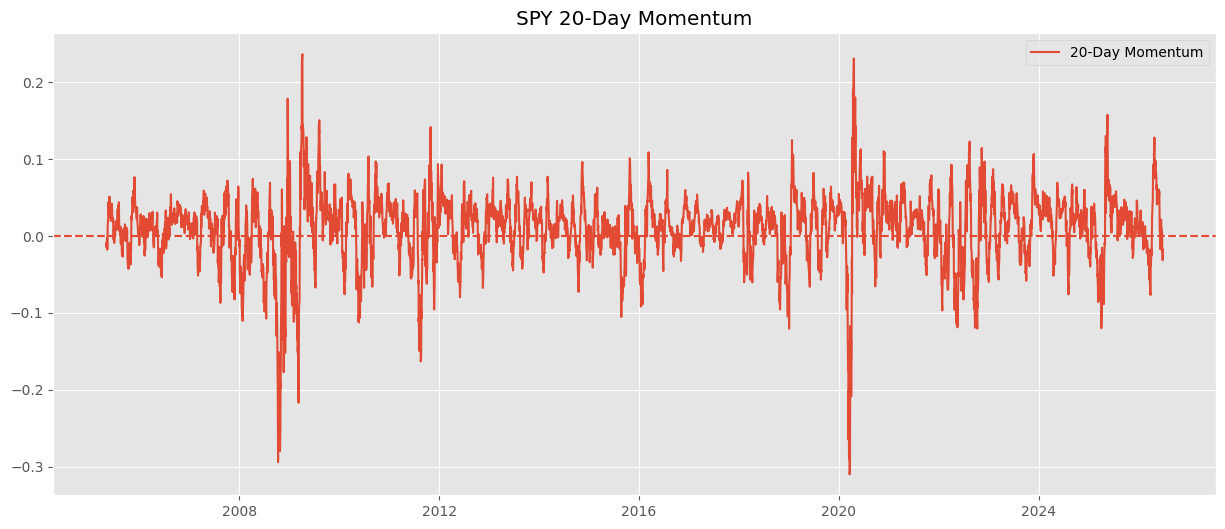

In [20]:
plt.figure(figsize=(15,6))
plt.plot(features.index,features["SPY_Mom20"],label="20-Day Momentum")
plt.axhline(0,linestyle="--")
plt.title("SPY 20-Day Momentum")
plt.legend()
plt.show()

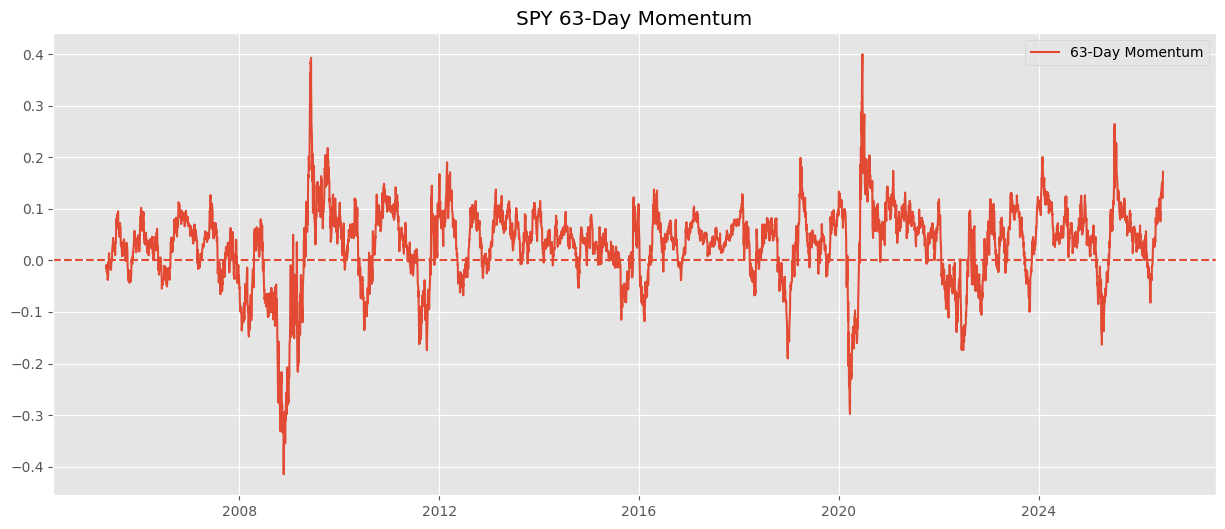

In [21]:
plt.figure(figsize=(15,6))
plt.plot(features.index,features["SPY_Mom63"],label="63-Day Momentum")
plt.axhline(0,linestyle="--")
plt.title("SPY 63-Day Momentum")
plt.legend()
plt.show()

In [22]:
rolling_corr_spy_tlt = (
    features["SPY_Return"]
    .rolling(window=20)
    .corr(features["TLT_Return"]))

rolling_corr_spy_tlt.name = "SPY_TLT_Corr20"
rolling_corr_spy_tlt.head(25)

,SPY_TLT_Corr20
Date,
2005-05-02,NaN
2005-05-03,NaN
2005-05-04,NaN
2005-05-05,NaN
2005-05-06,NaN
2005-05-09,NaN
2005-05-10,NaN
2005-05-11,NaN
2005-05-12,NaN


In [23]:
features = pd.concat([features, rolling_corr_spy_tlt],axis=1)
features = features.dropna()

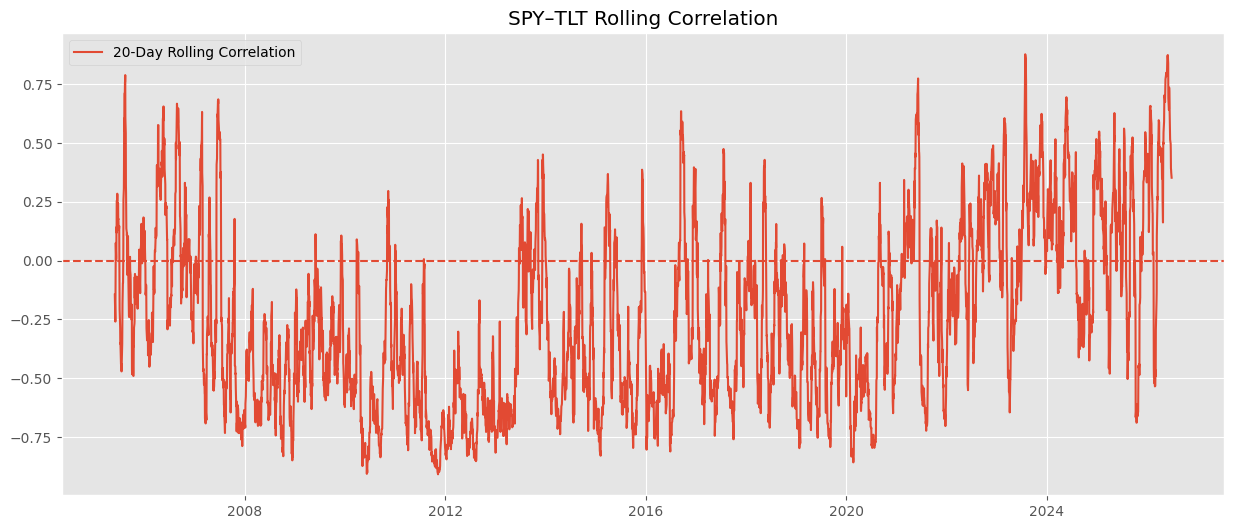

In [24]:
plt.figure(figsize=(15,6))
plt.plot(
    features.index,
    features["SPY_TLT_Corr20"],
    label="20-Day Rolling Correlation")
plt.axhline(0, linestyle="--")
plt.title("SPY–TLT Rolling Correlation")
plt.legend()
plt.show()

In [25]:
features["VIX_Return"].describe()

,VIX_Return
count,5304.000000
mean,0.000069
std,0.076062
min,-0.442449
25%,-0.041628
50%,-0.006188
75%,0.034513
max,0.768245


In [26]:
prices["^VIX"].describe()

,^VIX
count,5405.000000
mean,19.151219
std,8.568605
min,9.140000
25%,13.500000
50%,16.830000
75%,22.080000
max,82.690002


In [27]:
vix_level = prices["^VIX"].loc[features.index]
features["VIX_Level"] = vix_level

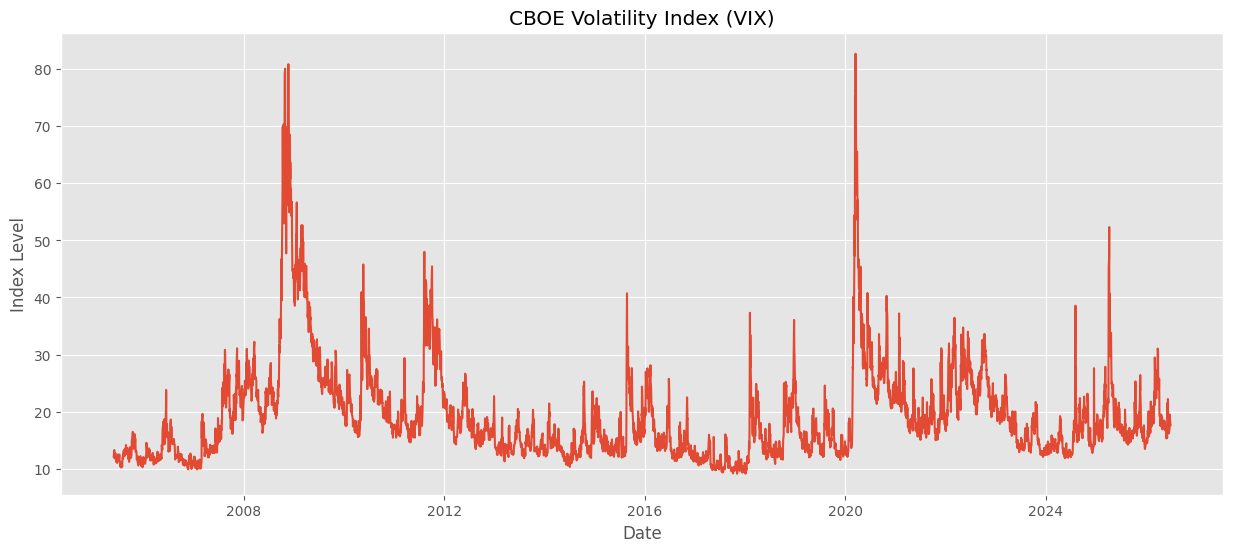

In [28]:
plt.figure(figsize=(15,6))
plt.plot(features.index,features["VIX_Level"])
plt.title("CBOE Volatility Index (VIX)")
plt.ylabel("Index Level")
plt.xlabel("Date")
plt.show()

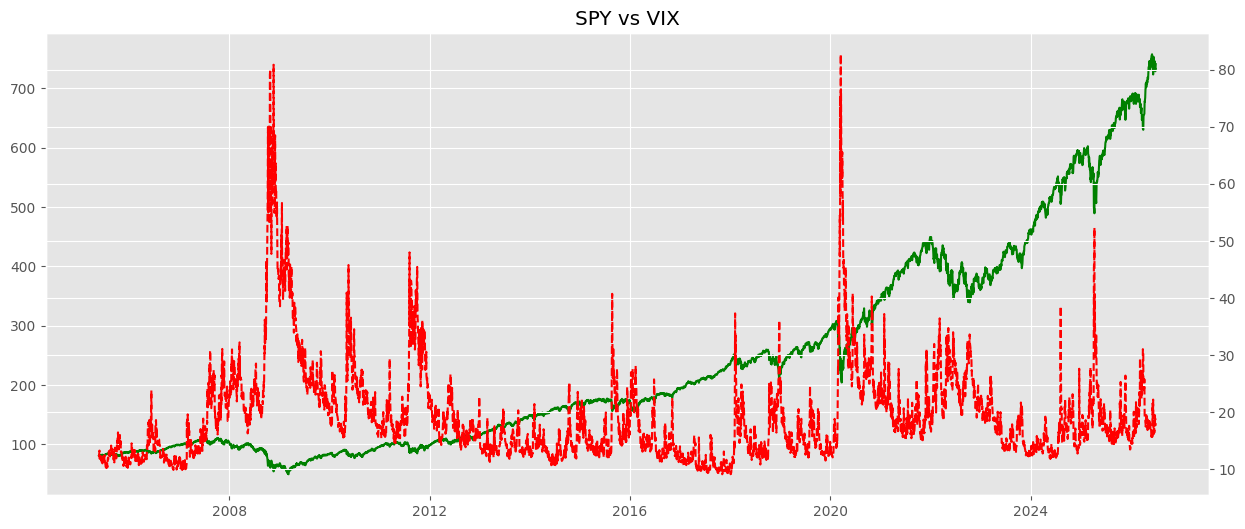

In [31]:
fig, ax1 = plt.subplots(figsize=(15,6))
ax1.plot(features.index,prices.loc[features.index, "SPY"],label="SPY", color='green')
ax2 = ax1.twinx()
ax2.plot(features.index,features["VIX_Level"],linestyle="--",label="VIX", color='red')
ax1.set_title("SPY vs VIX")
plt.show()